# 03 · Modelos de churn: comparación por costo de la decisión — Conecta+

**Pregunta:** ¿a quién contactar en los próximos 90 días?

**Criterio de selección (los "pesos" de la decisión):** no gana el modelo con más AUC sino el que más
**valor neto** produce al aplicar la regla de contacto con los supuestos del enunciado:

| Decisión | Cliente iba a cancelar | No iba a cancelar |
|---|---|---|
| Contactar | 0,40 × 12 × precio vigente − 25.000 | −25.000 |
| No contactar | 0 | 0 |

Contactar si **p > 25.000 / (4,8 × precio)** → Básico 0,218 · Estándar 0,149 · Premium 0,104 · Familiar 0,087.
La regla usa la probabilidad directamente, por eso todos los modelos se **calibran**.

**Validación temporal con origen móvil** (nunca se entrena con el futuro):
pliegue 1 entrena marzo → valida junio; pliegue 2 entrena marzo+junio → valida septiembre.
Calibración sigmoide fuera de pliegue con GroupKFold por cliente. Código: `conecta/modelado.py`, `conecta/negocio.py`.

In [1]:
import sys, warnings, pickle, logging
from pathlib import Path
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from conecta import io, gold, modelado as m, negocio, config
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, TINTA, TENUE = "#2a78d6", "#eb6834", "#2b2b2b", "#8a8a86"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TENUE, "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "xtick.color": TENUE, "ytick.color": TENUE,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
LAKE = RAIZ / "lake"
F = io.read(LAKE, "gold", "features"); F["fecha_corte"] = pd.to_datetime(F["fecha_corte"])
print(F.groupby(["fecha_corte", "conjunto"]).agg(clientes=("cliente_id", "size"), tasa_churn=("churn_90d", "mean")).round(3))
print(f"{len(gold.NUM)} variables numéricas + {len(gold.CAT)} categóricas (todas calculadas al corte)")

                           clientes  tasa_churn
fecha_corte conjunto                           
2025-03-31  entrenamiento      1447       0.103
2025-06-30  entrenamiento      1620       0.138
2025-09-30  entrenamiento      1743       0.157
2025-12-31  puntuar            1558        <NA>
40 variables numéricas + 5 categóricas (todas calculadas al corte)


## 1. Comparación de 15 candidatos

In [2]:
res, preds, mods = m.comparar(LAKE)
rk = m.ranking(res)
tabla = rk[rk.version == "calibrada"].drop(columns="version")
tabla.round(4)

,modelo,pct_max_prom,pct_max_min,valor_neto_prom,roc_auc_prom,pr_auc_prom,brier_prom,pct_max_2025-06-30,pct_max_2025-09-30
1,02_logistica_l1,0.3422,0.2909,13671780.0,0.7174,0.3777,0.1120,0.2909,0.3935
3,04_random_forest,0.3411,0.2478,13804180.0,0.7150,0.3180,0.1167,0.2478,0.4344
4,01_logistica,0.3405,0.2705,13682280.0,0.6993,0.3603,0.1138,0.2705,0.4104
8,13_logistica_peso_valor,0.3260,0.2439,13162400.0,0.6845,0.3346,0.1174,0.2439,0.4080
10,12_ensamble_log_rf_lgbm,0.3223,0.2259,13078020.0,0.7142,0.3482,0.1145,0.2259,0.4187
11,05_extra_trees,0.3177,0.2383,12824960.0,0.7062,0.3307,0.1162,0.2383,0.3971
14,07_lightgbm,0.3021,0.2191,12229420.0,0.6710,0.2829,0.1199,0.2191,0.3852
15,08_knn,0.3010,0.2442,12073560.0,0.6653,0.2738,0.1207,0.2442,0.3578
16,14_lightgbm_peso_valor,0.3008,0.2198,12169220.0,0.6750,0.2863,0.1199,0.2198,0.3819
18,06_hist_gradient_boosting,0.2970,0.1951,12105940.0,0.6681,0.2832,0.1202,0.1951,0.3989


In [3]:
r9 = res[(res.valida == "2025-09-30") & (res.version == "calibrada")].iloc[0]
r6 = res[(res.valida == "2025-06-30") & (res.version == "calibrada")].iloc[0]
print(f"Valor máximo posible (contactar solo a quienes cancelan): jun {r6.valor_maximo_oraculo/1e6:.1f} M · sep {r9.valor_maximo_oraculo/1e6:.1f} M COP")
print(f"Contactar a todos: jun {r6.valor_contactar_todos/1e6:.1f} M · sep {r9.valor_contactar_todos/1e6:.1f} M COP")

Valor máximo posible (contactar solo a quienes cancelan): jun 35.2 M · sep 43.5 M COP
Contactar a todos: jun 0.3 M · sep 6.8 M COP


**Ajuste por cambio de prevalencia (prior shift).** La tasa de churn sube cada trimestre (10,3 % → 13,8 % → 15,7 %),
así que los modelos tienden a subestimar. Se probó llevar las probabilidades a la tasa del último corte conocido:

In [4]:
pv = rk.pivot(index="modelo", columns="version", values="pct_max_prom")
pv["diferencia"] = pv["ajuste_prior"] - pv["calibrada"]
pv.sort_values("calibrada", ascending=False).round(4)

version,ajuste_prior,calibrada,diferencia
modelo,,,
02_logistica_l1,0.3565,0.3422,0.0143
04_random_forest,0.3421,0.3411,0.0010
01_logistica,0.3318,0.3405,-0.0087
13_logistica_peso_valor,0.3227,0.3260,-0.0033
12_ensamble_log_rf_lgbm,0.3398,0.3223,0.0175
05_extra_trees,0.3345,0.3177,0.0169
07_lightgbm,0.2971,0.3021,-0.0051
08_knn,0.3085,0.3010,0.0076
14_lightgbm_peso_valor,0.3022,0.3008,0.0014


El ajuste ayuda a unos modelos y perjudica a otros: **no se aplica** (no hay evidencia consistente). Queda como riesgo a monitorear.

## 2. ¿Hay un ganador claro? Bootstrap del valor neto

In [5]:
top = ["02_logistica_l1", "04_random_forest", "12_ensamble_log_rf_lgbm", "01_logistica", "05_extra_trees"]
for _, cva in m.PLIEGUES:
    va = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
    P = {k: preds[(cva, k, "calibrada")] for k in top}
    print(f"Validación {cva} — diferencia de valor vs logística L1 (IC 95 %)")
    display(m.bootstrap_valor(va.churn_90d.astype(int), va.precio_plan, P, "02_logistica_l1").round(3))

Validación 2025-06-30 — diferencia de valor vs logística L1 (IC 95 %)


,modelo,delta_valor_vs_02_logistica_l1,ic95_bajo,ic95_alto,prob_mejor_que_ref
2,01_logistica,-671438.36,-2538647.0,1180585.0,0.244
0,04_random_forest,-1487659.20,-3475158.0,466429.0,0.067
3,05_extra_trees,-1816495.76,-3803606.0,194064.0,0.031
1,12_ensamble_log_rf_lgbm,-2246320.80,-4210065.0,-287627.0,0.010


Validación 2025-09-30 — diferencia de valor vs logística L1 (IC 95 %)


,modelo,delta_valor_vs_02_logistica_l1,ic95_bajo,ic95_alto,prob_mejor_que_ref
0,04_random_forest,1709126.60,-336578.0,3699365.0,0.944
1,12_ensamble_log_rf_lgbm,1059918.44,-762135.0,2812647.0,0.872
2,01_logistica,732460.44,-246128.0,1894845.0,0.916
3,05_extra_trees,148513.24,-2348939.0,2474872.0,0.556


**Empate técnico** entre Random Forest y logística L1: RF gana en septiembre, L1 en junio, y los intervalos
incluyen 0. Son de familias distintas (árboles vs lineal), así que se prueba **promediarlos**.

In [6]:
filas = []
for w in [0, 0.3, 0.5, 0.7, 1]:
    for _, cva in m.PLIEGUES:
        va = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
        p = w * preds[(cva, "02_logistica_l1", "calibrada")] + (1 - w) * preds[(cva, "04_random_forest", "calibrada")]
        filas.append({"peso_logistica_l1": w, "valida": cva, **m.metricas(va.churn_90d.astype(int), p, va.precio_plan)})
mez = pd.DataFrame(filas)
mez.pivot_table(index="peso_logistica_l1", columns="valida", values="pct_del_maximo").assign(
    promedio=lambda d: d.mean(axis=1), peor=lambda d: d.iloc[:, :2].min(axis=1)).round(4)

valida,2025-06-30,2025-09-30,promedio,peor
peso_logistica_l1,,,,
0.0,0.2478,0.4344,0.3411,0.2478
0.3,0.2901,0.4372,0.3636,0.2901
0.5,0.2906,0.4387,0.3647,0.2906
0.7,0.2950,0.4238,0.3594,0.2950
1.0,0.2909,0.3935,0.3422,0.2909


### Modelo elegido: ensamble **logística L1 + Random Forest, 50/50**
- Mayor valor promedio entre pliegues (36,5 % del máximo) y mejor que cada uno por separado en el promedio y en el peor pliegue.
- Peso 50/50 **fijado a priori** (no se ajustó mirando la validación); la grilla confirma que además es el mejor de los probados.
- Combina la estabilidad y calibración de la logística con las interacciones que captura el bosque.
- Sigue siendo explicable: coeficientes de la logística + importancia por permutación.

## 3. Validación del modelo elegido (entrenado mar+jun → septiembre)

In [7]:
tr = F[F.fecha_corte.isin(pd.to_datetime(m.CORTES_TRAIN))].reset_index(drop=True)
va = F[F.fecha_corte == pd.Timestamp(m.CORTE_VALID)].reset_index(drop=True)
ens = m.entrenar(tr)
p_va = ens.predict_proba(va[m.X_COLS])[:, 1]
y_va = va.churn_90d.astype(int)
r = m.metricas(y_va, p_va, va.precio_plan)
pd.Series(r).to_frame("septiembre").T.round(4)

,roc_auc,pr_auc,brier,log_loss,prob_media,tasa_real,valor_neto,pct_del_maximo,contactados,pct_contactados,churners_contactados,recall_churn_contactado,precision_contacto,valor_contactar_todos,valor_maximo_oraculo
septiembre,0.7503,0.4343,0.1139,0.3755,0.1461,0.1572,19084360.0,0.4387,695.0,0.3987,183.0,0.6679,0.2633,6775080.0,43500080.0


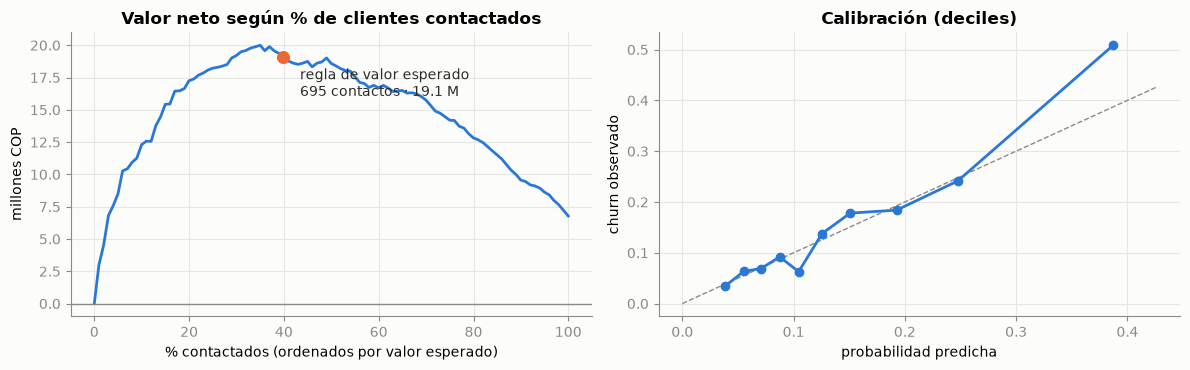

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cv = negocio.curva_valor(y_va, p_va, va.precio_plan)
ax = axes[0]
ax.plot(cv.pct_contactados * 100, cv.valor_neto / 1e6, color=AZUL)
ax.axhline(0, color=TENUE, linewidth=1)
ax.scatter([r["pct_contactados"] * 100], [r["valor_neto"] / 1e6], color=NARANJA, s=70, zorder=3)
ax.annotate(f"regla de valor esperado\n{r['contactados']} contactos · {r['valor_neto']/1e6:.1f} M",
            (r["pct_contactados"] * 100, r["valor_neto"] / 1e6), xytext=(12, -28), textcoords="offset points", color=TINTA)
ax.set_title("Valor neto según % de clientes contactados"); ax.set_xlabel("% contactados (ordenados por valor esperado)")
ax.set_ylabel("millones COP")
ax = axes[1]
bins = pd.qcut(p_va, 10, duplicates="drop")
cal = pd.DataFrame({"p": p_va, "y": y_va}).groupby(bins, observed=True).mean()
ax.plot([0, cal.p.max() * 1.1], [0, cal.p.max() * 1.1], color=TENUE, linewidth=1, linestyle="--")
ax.plot(cal.p, cal.y, color=AZUL, marker="o", markersize=6)
ax.set_title("Calibración (deciles)"); ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("churn observado")
plt.tight_layout(); plt.show()

La regla de valor esperado cae cerca del máximo de la curva: no hace falta optimizar un umbral a mano.
La calibración sigue la diagonal; en los deciles altos el modelo subestima un poco (efecto del churn creciente).

## 4. ¿Por qué se van? Factores del modelo

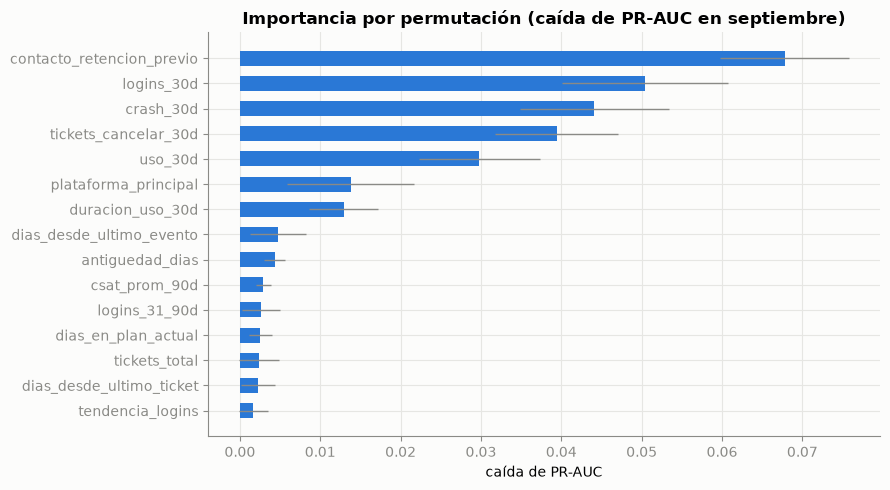

,variable,importancia,desv,efecto_logistica
8,contacto_retencion_previo,0.0678,0.0081,0.261
30,logins_30d,0.0504,0.0103,-0.447
35,crash_30d,0.0441,0.0093,0.030
18,tickets_cancelar_30d,0.0394,0.0077,0.319
33,uso_30d,0.0298,0.0075,-0.343
44,plataforma_principal,0.0138,0.0079,NaN
34,duracion_uso_30d,0.0129,0.0043,-0.111
37,dias_desde_ultimo_evento,0.0047,0.0035,0.129
0,antiguedad_dias,0.0043,0.0013,-0.020
29,csat_prom_90d,0.0029,0.0009,-0.024


In [9]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
pr_auc = lambda est, X, y: average_precision_score(y, est.predict_proba(X)[:, 1])
pi = permutation_importance(ens, va[m.X_COLS], y_va, scoring=pr_auc, n_repeats=10, random_state=0)
imp = pd.DataFrame({"variable": m.X_COLS, "importancia": pi.importances_mean, "desv": pi.importances_std})
imp = imp.sort_values("importancia", ascending=False).head(15)
# dirección del efecto: coeficiente de la logística L1 (variables estandarizadas)
l1 = ens.modelos["02_logistica_l1"].calibrated_classifiers_[0].estimator
nombres = l1[:-1].get_feature_names_out()
coef = pd.Series(l1[-1].coef_[0], index=[n.split("__", 1)[1] for n in nombres])
imp["efecto_logistica"] = imp.variable.map(lambda v: coef.get(v, np.nan)).round(3)
fig, ax = plt.subplots(figsize=(9, 5))
d = imp.iloc[::-1]
ax.barh(d.variable, d.importancia, xerr=d.desv, color=AZUL, height=0.6, error_kw={"ecolor": TENUE, "lw": 1})
ax.set_title("Importancia por permutación (caída de PR-AUC en septiembre)"); ax.set_xlabel("caída de PR-AUC")
plt.tight_layout(); plt.show()
imp.round(4)

Lectura (`efecto_logistica` positivo = más riesgo): dominan el **contacto de retención previo** (reactivo: el cliente ya pidió irse),
**pocos logins y poco uso en 30 días**, los **cierres de la app (CRASH_ON_START, versión 5.4.0)** y la **intención de cancelar**
detectada por el NLP en tickets. El sarcasmo y la frustración aportan poco una vez que se conoce la intención (coherente con el notebook 02).
El efecto de `crash_30d` es casi nulo en la logística pero fuerte en el bosque (interacción con plataforma Android).

## 5. Modelo final y predicciones (3 cortes → 2025-12-31)

In [10]:
trf = F[F.conjunto == "entrenamiento"].reset_index(drop=True)
sc = F[F.conjunto == "puntuar"].reset_index(drop=True)
final = m.entrenar(trf)
pred = m.predecir(final, sc)
m.validar_predicciones(pred, io.read(LAKE, "silver", "clientes_a_puntuar"))
pred[["cliente_id", "probabilidad", "contactar"]].sort_values("cliente_id").to_csv(RAIZ / "predicciones.csv", index=False)
print(f"predicciones.csv: {len(pred)} clientes · probabilidad media {pred.probabilidad.mean():.3f} · "
      f"contactar {pred.contactar.sum()} ({pred.contactar.mean():.0%})")
pred.groupby("plan").agg(clientes=("cliente_id", "size"), prob_media=("probabilidad", "mean"),
                         contactar=("contactar", "sum"), umbral=("precio_plan", lambda s: negocio.umbral(s.iloc[0]))).round(3)

predicciones.csv: 1558 clientes · probabilidad media 0.149 · contactar 522 (34%)


,clientes,prob_media,contactar,umbral
plan,,,,
Basico,449,0.153,82,0.218
Estandar,524,0.144,156,0.149
Familiar,257,0.157,148,0.087
Premium,328,0.143,136,0.104


In [11]:
k = pred.contactar == 1
print(f"Costo de los contactos: {k.sum() * config.COSTO_CONTACTO / 1e6:.1f} M COP")
print(f"Valor esperado neto de la decisión (según el modelo): {pred.loc[k, 'valor_esperado_contacto'].sum() / 1e6:.1f} M COP")
print(f"Referencia validada en septiembre (sin exclusión): {r['valor_neto']/1e6:.1f} M COP ({r['pct_del_maximo']:.0%} del máximo posible)")

Costo de los contactos: 13.1 M COP
Valor esperado neto de la decisión (según el modelo): 12.1 M COP
Referencia validada en septiembre (sin exclusión): 19.1 M COP (44% del máximo posible)


### Política: no volver a contactar a quien ya recibió una oferta de retención
Decisión de negocio (`config.EXCLUIR_CONTACTADOS_PREVIOS`). Estos clientes tienen el mayor riesgo, pero ya
rechazaron una oferta (el 94 % de los contactados históricos canceló igual). Bajo los supuestos del enunciado
(40 % de éxito para cualquiera) excluirlos **cuesta valor**; se documenta el costo medido en validación:

In [12]:
filas = []
for cortes_tr, cva in m.PLIEGUES:
    t_ = F[F.fecha_corte.isin(pd.to_datetime(cortes_tr))].reset_index(drop=True)
    v_ = F[F.fecha_corte == pd.Timestamp(cva)].reset_index(drop=True)
    p_ = m.entrenar(t_).predict_proba(v_[m.X_COLS])[:, 1]
    y_, pr_ = v_.churn_90d.astype(int), v_.precio_plan
    ex = v_.contacto_retencion_previo.to_numpy() == 1
    con = negocio.valor_realizado(y_, negocio.decidir(p_, pr_), pr_)
    sin = negocio.valor_realizado(y_, negocio.decidir(p_, pr_, ex), pr_)
    filas.append({"valida": cva, "contactados_previos": int(ex.sum()), "churn_de_ellos": y_[ex].mean(),
                  "valor_incluyendolos_M": con / 1e6, "valor_excluyendolos_M": sin / 1e6, "diferencia_M": (sin - con) / 1e6})
pd.DataFrame(filas).round(3)

,valida,contactados_previos,churn_de_ellos,valor_incluyendolos_M,valor_excluyendolos_M,diferencia_M
0,2025-06-30,24,0.583,10.217,8.129,-2.087
1,2025-09-30,39,0.538,19.084,16.381,-2.703


In [13]:
print(f"Diciembre: {pred.excluido_por_contacto_previo.sum()} clientes con contacto previo; "
      f"{((pred.excluido_por_contacto_previo == 1) & (pred.valor_esperado_contacto > 0)).sum()} habrían entrado a la lista y se excluyen.")

Diciembre: 49 clientes con contacto previo; 46 habrían entrado a la lista y se excluyen.


## 6. Sensibilidad a los supuestos de negocio (cambio en vivo)

In [14]:
filas = []
for exito in [0.3, 0.4, 0.5]:
    for costo in [20_000, 25_000, 35_000]:
        ve = pred.probabilidad * exito * config.MESES_VALOR_RETENCION * pred.precio_plan - costo
        kk = (ve > 0) & (pred.excluido_por_contacto_previo == 0)
        # valor realizado en septiembre con esos mismos supuestos
        ve_va = p_va * exito * 12 * va.precio_plan - costo
        kv = ((ve_va > 0) & ~((va.contacto_retencion_previo == 1) & config.EXCLUIR_CONTACTADOS_PREVIOS)).astype(int)
        real = float(np.sum(kv * (y_va * exito * 12 * va.precio_plan - costo)))
        filas.append({"tasa_exito": exito, "costo_contacto": costo, "contactar_dic": int(kk.sum()),
                      "valor_esperado_dic_M": ve[kk].sum() / 1e6, "valor_real_sep_M": real / 1e6})
pd.DataFrame(filas).round(2)

,tasa_exito,costo_contacto,contactar_dic,valor_esperado_dic_M,valor_real_sep_M
0,0.3,20000,479,8.47,11.85
1,0.3,25000,363,6.40,8.84
2,0.3,35000,190,3.77,5.20
3,0.4,20000,675,15.09,19.98
4,0.4,25000,522,12.12,16.38
5,0.4,35000,332,7.96,11.49
6,0.5,20000,853,22.65,29.12
7,0.5,25000,675,18.86,24.97
8,0.5,35000,449,13.34,19.30


## 7. Registro en MLflow

In [15]:
import os, mlflow
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["conecta_churn"], order_by=["metrics.pct_max_prom DESC"])
if runs.empty:
    runs = m.registrar_mlflow(LAKE, uri=f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}")
runs[["tags.mlflow.runName", "metrics.pct_max_prom", "metrics.pct_del_maximo_06", "metrics.pct_del_maximo_09",
      "metrics.valor_neto_09", "metrics.roc_auc_09", "metrics.pr_auc_09", "metrics.brier_09"]].round(4)

,tags.mlflow.runName,metrics.pct_max_prom,metrics.pct_del_maximo_06,metrics.pct_del_maximo_09,metrics.valor_neto_09,metrics.roc_auc_09,metrics.pr_auc_09,metrics.brier_09
0,20_ensamble_elegido_l1_rf_50_50,0.3647,0.2906,0.4387,19084360.0,0.7503,0.4343,0.1139
1,02_logistica_l1,0.3422,0.2909,0.3935,17116280.0,0.7362,0.4187,0.1142
2,04_random_forest,0.3411,0.2478,0.4344,18896160.0,0.7432,0.3754,0.1186
3,01_logistica,0.3405,0.2705,0.4104,17854600.0,0.7284,0.4064,0.1154
4,13_logistica_peso_valor,0.3260,0.2439,0.4080,17749480.0,0.7154,0.3753,0.1213
5,12_ensamble_log_rf_lgbm,0.3223,0.2259,0.4187,18214800.0,0.7436,0.4109,0.1147
6,05_extra_trees,0.3177,0.2383,0.3971,17272920.0,0.7243,0.3778,0.1190
7,07_lightgbm,0.3021,0.2191,0.3852,16757440.0,0.7044,0.3449,0.1225
8,08_knn,0.3010,0.2442,0.3578,15563960.0,0.6772,0.2774,0.1267
9,14_lightgbm_peso_valor,0.3008,0.2198,0.3819,16611320.0,0.7030,0.3465,0.1232


**Corrida elegida: `20_ensamble_elegido_l1_rf_50_50`.** Tiene el mayor % del valor máximo promedio, es mejor que
sus dos componentes en ambos pliegues y su calibración (Brier) es tan buena como la de la logística. La línea base
(tasa por plan × segmento) confirma que el modelo aporta: multiplica por ~2,5 el valor neto.